In [43]:
import matplotlib.pyplot as plt
import numpy as np

from scipy.linalg import lu_factor, lu_solve
from scipy.optimize import curve_fit


np.random.seed(42)

In [44]:
import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

In [45]:
L = 1
Tf = 10
nt = 50000

D = 1

#dx = L/(nx-1)
dt = Tf/nt

wanted_r = 0.5

dx = np.sqrt(D*dt/wanted_r)
nx = int(L/dx) + 1
dx = L/(nx-1)     

r = D*dt/(dx**2)
h = 1

print("Time scale coeff: ", L*L/D)
print("dx: ", dx)
print("dt: ", dt)
print("r: ", r)

plt.figure(figsize=(3.4, 2.2))

x_array = np.linspace(0, L, nx)
t_array = np.linspace(0,Tf,nt)


A = np.zeros((nx, nx))
B = np.zeros((nx, nx))

# Nodi interni
for i in range(1, nx-1):
    A[i, i-1] = -r/2
    A[i, i]   = 1 + r
    A[i, i+1] = -r/2

    B[i, i-1] = r/2
    B[i, i]   = 1 - r
    B[i, i+1] = r/2

# Boundary sinistra (Dirichlet)
A[0,0] = 1
#B[0,0] = 1
B[0,:] = 0

# Boundary destra (Robin)
A[-1, -2] = -2*r
A[-1, -1] = 1 + 2*r*(1+h*dx)

B[-1, -2] = 2*r
B[-1, -1] = 1 - 2*r*(1+h*dx)

lu, piv = lu_factor(A)

T = np.zeros(shape=(nx,nt))

# Initial condition
T[:,0] = 0

# Right boundary 
f = np.zeros(nt)
f[0] = 1
T[0,0] = f[0]

for n in range(1,nt):
    b = B @ T[:,n-1]
    b[0] = f[n] # impongo dirichlet
    T[:,n] = lu_solve((lu, piv), b)


Time scale coeff:  1.0
dx:  0.02
dt:  0.0002
r:  0.5


<Figure size 340x220 with 0 Axes>

In [46]:
from scipy.optimize import brentq

def f(x, h, L):
    return x - h * np.tan(x * L)


def trova_radici(h, L, n_radici, x_max=50):
    radici = []
    
    # suddividi il dominio in tanti intervalli
    x_vals = np.linspace(0.001, x_max, 10000)
    
    for i in range(len(x_vals) - 1):
        x1, x2 = x_vals[i], x_vals[i+1]
        
        # evita discontinuità (tan diverge)
        if np.isfinite(f(x1, h, L)) and np.isfinite(f(x2, h, L)):
            if f(x1, h, L) * f(x2, h, L) < 0:
                try:
                    root = brentq(f, x1, x2, args=(h, L))
                    radici.append(root)
                    
                    if len(radici) >= n_radici:
                        break
                except ValueError:
                    pass
    
    return radici

radici = trova_radici(h, L, 3)
print(radici)

radici = [0.86, 3.43]

radici = np.array(radici)



s_array = radici*radici*D

[1.5707963267962275, 4.493409457909534, 4.712388980383693]


In [47]:
def func(x, a, b):
    return a*np.exp(-s_array[0]*(x)) + b*np.exp(-s_array[1]*(x))
    
popt, pcov = curve_fit(func, t_array[7000:], T[nx-1,7000:], p0=s_array)
print(popt)


[4.29542231e-07 1.54057743e+01]


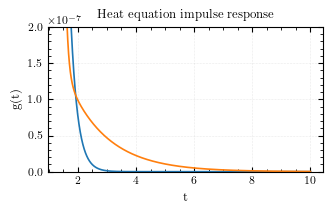

In [48]:
plt.figure(figsize=(3.4, 2.2))
plt.plot(t_array[7000:], T[nx-1,7000:])

plt.plot(t_array[7000:], func(t_array[7000:],*popt))

plt.ylim([0,0.0000002])
plt.grid()
plt.title("Heat equation impulse response")

plt.xlabel("t")
plt.ylabel("g(t)")
plt.tight_layout()
plt.minorticks_on()
plt.savefig("assets/funzione_trasferimento_risposta_impulso.pdf")
plt.show()